<a href="https://colab.research.google.com/github/ihinck413/Econ-5120/blob/main/Econ_5200_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

file_path = '/content/DJIA_Components_Oct2026.xlsx'
xls = pd.ExcelFile(file_path)
print("Sheet names:", xls.sheet_names)

df_components = pd.read_excel(file_path, sheet_name=0)
display(df_components.head(10))
print("Columns:", df_components.columns.tolist())

Sheet names: ['DJIA Components', 'Sector Summary']


,"Dow Jones Industrial Average — Components (as of October 19, 2026)",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,#,Company,Ticker,Exchange,GICS Sector,Date Added to DJIA
2,1,3M Company,MMM,NYSE,Industrials,1976-08-09 00:00:00
3,2,Alphabet Inc. (Class A),GOOGL,Nasdaq,Communication Services,2026-06-29 00:00:00
4,3,Amazon.com Inc.,AMZN,Nasdaq,Consumer Discretionary,2024-02-26 00:00:00
5,4,American Express Company,AXP,NYSE,Financials,1982-08-30 00:00:00
6,5,Amgen Inc.,AMGN,Nasdaq,Health Care,2020-08-31 00:00:00
7,6,Apple Inc.,AAPL,Nasdaq,Information Technology,2015-03-19 00:00:00
8,7,Boeing Company,BA,NYSE,Industrials,1987-03-12 00:00:00
9,8,Caterpillar Inc.,CAT,NYSE,Industrials,1991-05-06 00:00:00


Columns: ['Dow Jones Industrial Average — Components (as of October 19, 2026)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


Monthly Returns

In [2]:
import pandas as pd
import yfinance as yf

df_cleaned = pd.read_excel(file_path, sheet_name=0, skiprows=1)

ticker_col_idx = None
for col in df_cleaned.columns:
    if df_cleaned[col].iloc[0] == 'Ticker':
        ticker_col_idx = col
        break

if ticker_col_idx is not None:
    tickers = df_cleaned[ticker_col_idx].iloc[1:].dropna().unique().tolist()
else:
    tickers = df_cleaned.iloc[:, 2].dropna().unique().tolist()
    if 'Ticker' in tickers:
        tickers.remove('Ticker')

tickers = [str(t).strip().upper() for t in tickers if pd.notna(t)]
tickers = [t for t in tickers if t.isalpha() and t != '']

print(f"Successfully extracted {len(tickers)} valid tickers:")
print(tickers)

start_date = "1989-11-30"
end_date = "2026-09-30"

print(f"Downloading monthly historical data...")
data = yf.download(tickers, start=start_date, end=end_date, interval='1mo', auto_adjust=False)

adj_close = data['Adj Close']

monthly_returns = adj_close.pct_change(fill_method=None)

print(f"Shape of monthly returns DataFrame: {monthly_returns.shape}")
display(monthly_returns.head(10))

Successfully extracted 30 valid tickers:
['MMM', 'GOOGL', 'AMZN', 'AXP', 'AMGN', 'AAPL', 'BA', 'CAT', 'CVX', 'CSCO', 'KO', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'MCD', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'CRM', 'SHW', 'TRV', 'UNH', 'V', 'WMT', 'DIS']


[*********************100%***********************]  30 of 30 completed

Shape of monthly returns DataFrame: (442, 30)


Ticker,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,...,MRK,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,WMT
Date,,,,,,,,,,,,,,,,,,,,,
1989-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1990-01-01,-0.035462,-0.045918,NaN,-0.146954,-0.002104,-0.038179,NaN,NaN,-0.012915,-0.069350,...,-0.067741,0.063218,-0.051643,NaN,-0.083106,-0.054545,-0.090909,-0.237112,NaN,-0.050138
1990-02-01,0.003221,0.229947,NaN,-0.021009,0.083269,0.094809,NaN,NaN,0.014316,0.051621,...,-0.053633,0.067568,0.123762,NaN,-0.001953,0.002035,0.125581,0.013513,NaN,0.032258
1990-03-01,0.183825,0.073913,NaN,-0.115879,0.123288,0.008247,NaN,0.010752,0.005587,0.014840,...,0.023065,0.121518,0.197760,NaN,0.060666,0.092664,-0.010892,0.040000,NaN,0.075458
1990-04-01,-0.021738,0.036437,NaN,0.062892,-0.027875,0.009114,NaN,0.010638,-0.024074,-0.004361,...,0.053956,0.047405,0.014759,NaN,0.049060,-0.010601,-0.044304,0.102564,NaN,0.050263
1990-05-01,0.050526,0.095704,NaN,0.078341,0.186708,0.091650,NaN,0.042115,0.074031,0.167422,...,0.135778,0.258620,0.141819,NaN,0.169911,0.084064,0.028697,0.406973,NaN,0.136020
1990-06-01,0.084848,0.108735,NaN,0.059204,0.065250,-0.214553,NaN,0.070702,0.005357,-0.005815,...,0.048338,0.041096,-0.019751,NaN,0.054463,0.056291,-0.002602,0.140497,NaN,0.107733
1990-07-01,-0.061453,0.109324,NaN,-0.052846,-0.012821,-0.065946,NaN,-0.037733,0.139061,-0.081830,...,0.027377,-0.125001,0.120521,NaN,0.000692,-0.031348,0.060870,0.101448,NaN,0.006012
1990-08-01,-0.116386,0.049275,NaN,-0.171673,-0.160561,-0.120205,NaN,-0.029410,-0.044094,-0.129649,...,-0.077776,-0.075188,-0.238372,NaN,-0.112391,-0.140865,-0.081968,-0.098289,NaN,-0.090448


Part A

In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

ff3_path = '/content/F-F_Research_Data_Factors 3.csv'
try:
    # Read file
    ff3_df = pd.read_csv(ff3_path, skiprows=3)
    ff3_df = ff3_df.rename(columns={ff3_df.columns[0]: 'Date'})
    # Strip whitespace from the Date column
    ff3_df['Date'] = ff3_df['Date'].astype(str).str.strip()
    # Filter only lines that represent monthly records (6 digits long, e.g., '192607')
    ff3_df = ff3_df[ff3_df['Date'].str.isdigit() & (ff3_df['Date'].str.len() == 6)]
    ff3_df['Date'] = pd.to_datetime(ff3_df['Date'], format='%Y%m')
    # Divide values by 100 as FF factors are given in percentages
    for col in ['Mkt-RF', 'SMB', 'HML', 'RF']:
        ff3_df[col] = pd.to_numeric(ff3_df[col], errors='coerce') / 100.0
    ff3_df = ff3_df.set_index('Date').dropna()
except Exception as e:
    print("Error loading FF3:", e)

# --- 2. Load Fama-French 5-factor data ---
ff5_path = '/content/F-F_Research_Data_5_Factors_2x3.csv'
try:
    ff5_df = pd.read_csv(ff5_path, skiprows=3)
    ff5_df = ff5_df.rename(columns={ff5_df.columns[0]: 'Date'})
    ff5_df['Date'] = ff5_df['Date'].astype(str).str.strip()
    # Filter only monthly records (6 digits)
    ff5_df = ff5_df[ff5_df['Date'].str.isdigit() & (ff5_df['Date'].str.len() == 6)]
    ff5_df['Date'] = pd.to_datetime(ff5_df['Date'], format='%Y%m')
    for col in ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']:
        ff5_df[col] = pd.to_numeric(ff5_df[col], errors='coerce') / 100.0
    ff5_df = ff5_df.set_index('Date').dropna()
except Exception as e:
    print("Error loading FF5:", e)

display(ff3_df.head(2))
display(ff5_df.head(2))

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07-01,0.0289,-0.0242,-0.0275,0.0022
1926-08-01,0.0264,-0.0144,0.0413,0.0025


,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,
1963-07-01,-0.0039,-0.0048,-0.0084,0.0064,-0.0115,0.0027
1963-08-01,0.0508,-0.0080,0.0172,0.0040,-0.0038,0.0025


Average R-square values:
CAPM    0.2694
FF3     0.3196
FF5     0.3429
dtype: float64


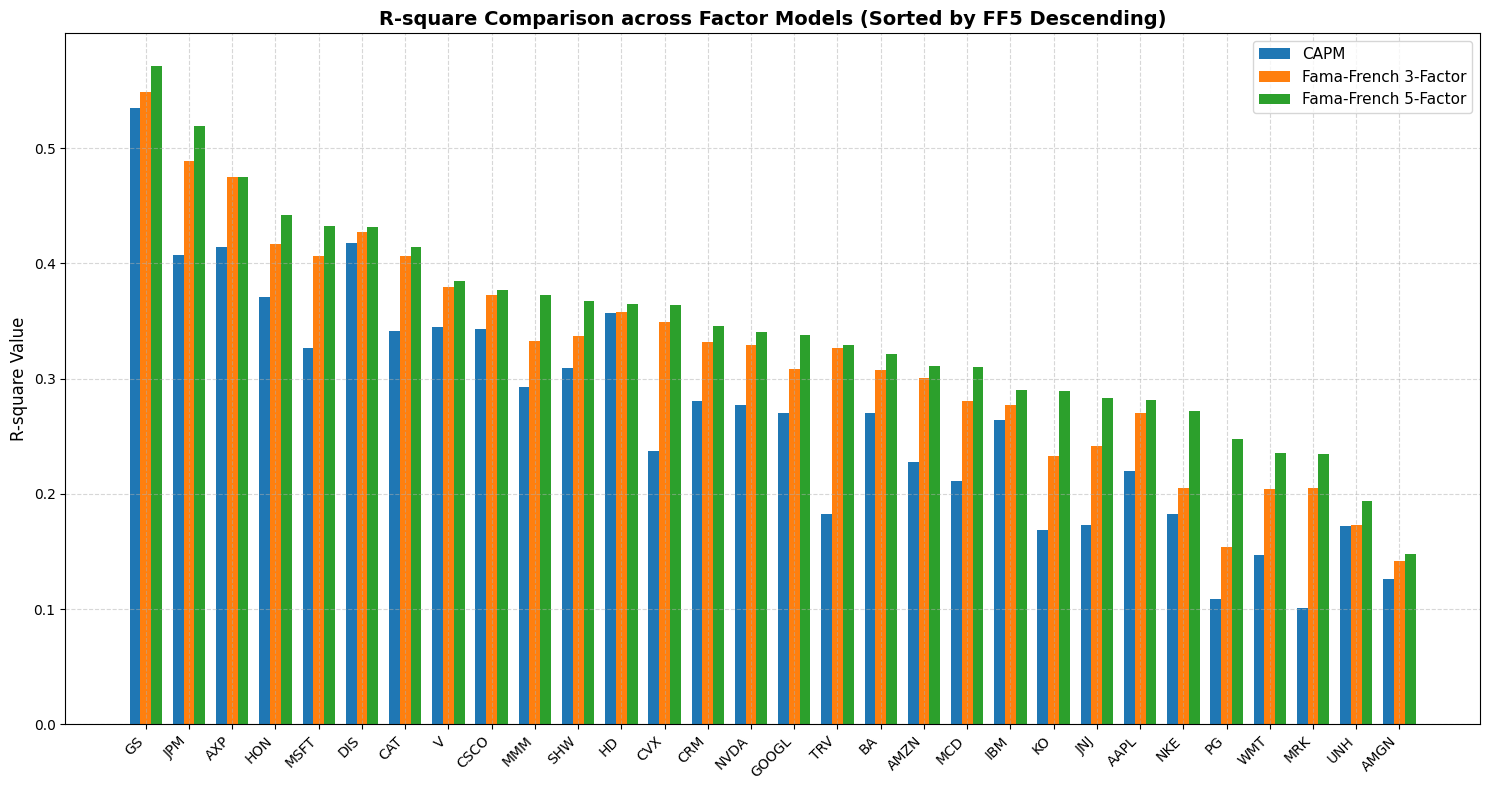

In [4]:
# Aligning stock returns with factor datasets and executing regressions

# Resample stock returns and factor dataframes to PeriodIndex ('M') for perfect matching
returns_m = monthly_returns.copy()
returns_m.index = returns_m.index.to_period('M')

ff3_m = ff3_df.copy()
ff3_m.index = ff3_m.index.to_period('M')

ff5_m = ff5_df.copy()
ff5_m.index = ff5_m.index.to_period('M')

r_squares = []

# Iterate over each ticker to compute OLS regressions
for ticker in tickers:
    y_raw = returns_m[ticker].dropna()
    if y_raw.empty:
        continue

    # Merge with FF3 (which contains Mkt-RF and RF)
    merged_3 = pd.concat([y_raw, ff3_m], axis=1, join='inner').dropna()
    if merged_3.empty:
        continue

    # Calculate excess returns: Ri - Rf
    y_excess = merged_3[ticker] - merged_3['RF']

    # 1. CAPM (Factor: Mkt-RF)
    X_capm = sm.add_constant(merged_3[['Mkt-RF']])
    model_capm = sm.OLS(y_excess, X_capm).fit()
    r2_capm = model_capm.rsquared

    # 2. FF3 (Factors: Mkt-RF, SMB, HML)
    X_ff3 = sm.add_constant(merged_3[['Mkt-RF', 'SMB', 'HML']])
    model_ff3 = sm.OLS(y_excess, X_ff3).fit()
    r2_ff3 = model_ff3.rsquared

    # 3. FF5 (Factors: Mkt-RF, SMB, HML, RMW, CMA)
    merged_5 = pd.concat([y_raw, ff5_m], axis=1, join='inner').dropna()
    if merged_5.empty:
        continue
    y_excess_5 = merged_5[ticker] - merged_5['RF']
    X_ff5 = sm.add_constant(merged_5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])
    model_ff5 = sm.OLS(y_excess_5, X_ff5).fit()
    r2_ff5 = model_ff5.rsquared

    r_squares.append({
        'Ticker': ticker,
        'CAPM': r2_capm,

        'FF3': r2_ff3,
        'FF5': r2_ff5
    })

df_r2 = pd.DataFrame(r_squares).set_index('Ticker')

# Calculate average R-square
avg_r2 = df_r2.mean()
print("Average R-square values:")
print(avg_r2.round(4))

# Sort by FF5 R-square descending
df_r2_sorted = df_r2.sort_values(by='FF5', ascending=False)

# Plotting the comparisons
fig, ax = plt.subplots(figsize=(15, 8))
width = 0.25
x = np.arange(len(df_r2_sorted))

ax.bar(x - width, df_r2_sorted['CAPM'], width, label='CAPM', color='#1f77b4')
ax.bar(x, df_r2_sorted['FF3'], width, label='Fama-French 3-Factor', color='#ff7f0e')
ax.bar(x + width, df_r2_sorted['FF5'], width, label='Fama-French 5-Factor', color='#2ca02c')

ax.set_ylabel('R-square Value', fontsize=12)
ax.set_title('R-square Comparison across Factor Models (Sorted by FF5 Descending)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_r2_sorted.index, rotation=45, ha='right', fontsize=10)
ax.legend(fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Part B

In [5]:
# Sum the monthly prices across the 30 components
sum_prices = adj_close.sum(axis=1)

# Calculate monthly returns of this price-weighted portfolio
djia_returns = sum_prices.pct_change(fill_method=None)

# Align with PeriodIndex ('M') to match factors
djia_returns_m = djia_returns.copy()
djia_returns_m.index = djia_returns_m.index.to_period('M')

# --- Regressions against Fama-French Factors ---

# 1. CAPM Regression
merged_djia_3 = pd.concat([djia_returns_m, ff3_m], axis=1, join='inner').dropna()
y_djia_excess = merged_djia_3[0] - merged_djia_3['RF']

X_djia_capm = sm.add_constant(merged_djia_3[['Mkt-RF']])
model_djia_capm = sm.OLS(y_djia_excess, X_djia_capm).fit()
r2_djia_capm = model_djia_capm.rsquared

# 2. FF3 Regression
X_djia_ff3 = sm.add_constant(merged_djia_3[['Mkt-RF', 'SMB', 'HML']])
model_djia_ff3 = sm.OLS(y_djia_excess, X_djia_ff3).fit()
r2_djia_ff3 = model_djia_ff3.rsquared

# 3. FF5 Regression
merged_djia_5 = pd.concat([djia_returns_m, ff5_m], axis=1, join='inner').dropna()
y_djia_excess_5 = merged_djia_5[0] - merged_djia_5['RF']

X_djia_ff5 = sm.add_constant(merged_djia_5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])
model_djia_ff5 = sm.OLS(y_djia_excess_5, X_djia_ff5).fit()
r2_djia_ff5 = model_djia_ff5.rsquared

# Display the results
print(f"DJIA Index CAPM R-square: {r2_djia_capm:.4f}")
print(f"DJIA Index FF 3-Factor R-square: {r2_djia_ff3:.4f}")
print(f"DJIA Index FF 5-Factor R-square: {r2_djia_ff5:.4f}")

DJIA Index CAPM R-square: 0.8734
DJIA Index FF 3-Factor R-square: 0.8914
DJIA Index FF 5-Factor R-square: 0.8942


In [6]:
import yfinance as yf
import pandas as pd
import statsmodels.api as sm

# --- 1. Download official DJIA monthly data ---
print("Downloading official DJIA index data... ")
dji_data = yf.download('^DJI', start=start_date, end=end_date, interval='1mo', auto_adjust=False)

# Extract Adjusted Close for the index
dji_adj_close = dji_data['Adj Close']

# Calculate monthly percentage returns
dji_returns = dji_adj_close.pct_change(fill_method=None)

# Align with PeriodIndex ('M') to match factors
dji_returns_m = dji_returns.copy()
dji_returns_m.index = dji_returns_m.index.to_period('M')

# --- 2. Regressions against Fama-French Factors for Official Index ---

# CAPM Regression
merged_dji_3 = pd.concat([dji_returns_m, ff3_m], axis=1, join='inner').dropna()
y_dji_excess = merged_dji_3['^DJI'] - merged_dji_3['RF']

X_dji_capm = sm.add_constant(merged_dji_3[['Mkt-RF']])
model_dji_capm = sm.OLS(y_dji_excess, X_dji_capm).fit()
r2_dji_capm = model_dji_capm.rsquared

# FF3 Regression
X_dji_ff3 = sm.add_constant(merged_dji_3[['Mkt-RF', 'SMB', 'HML']])
model_dji_ff3 = sm.OLS(y_dji_excess, X_dji_ff3).fit()
r2_dji_ff3 = model_dji_ff3.rsquared

# FF5 Regression
merged_dji_5 = pd.concat([dji_returns_m, ff5_m], axis=1, join='inner').dropna()
y_dji_excess_5 = merged_dji_5['^DJI'] - merged_dji_5['RF']

X_dji_ff5 = sm.add_constant(merged_dji_5[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])
model_dji_ff5 = sm.OLS(y_dji_excess_5, X_dji_ff5).fit()
r2_dji_ff5 = model_dji_ff5.rsquared

# --- 3. Comparison of Custom Proxy vs. Official DJIA ---
comparison_df = pd.DataFrame({
    'Model': ['CAPM', 'Fama-French 3-Factor', 'Fama-French 5-Factor'],
    'Custom Proxy R²': [r2_djia_capm, r2_djia_ff3, r2_djia_ff5],
    'Official DJIA (^DJI) R²': [r2_dji_capm, r2_dji_ff3, r2_dji_ff5]
})

display(comparison_df.round(4))


[*********************100%***********************]  1 of 1 completed


,Model,Custom Proxy R²,Official DJIA (^DJI) R²
0,CAPM,0.8734,0.8443
1,Fama-French 3-Factor,0.8914,0.8946
2,Fama-French 5-Factor,0.8942,0.9026


Part D

=== Empirical Factor Risk Premia (Monthly Mean) ===
lambda_Mkt-RF: 0.007498 (9.00% annualized)
lambda_SMB:    0.000410 (0.49% annualized)
lambda_HML:    0.001599 (1.92% annualized)

=== Cross-Sectional Regression Summary ===
Intercept (gamma_0): 0.003154 (Expected: 0.000000)
Slope (gamma_1):     1.440343 (Expected: 1.000000)
Cross-sectional R2:  0.2225



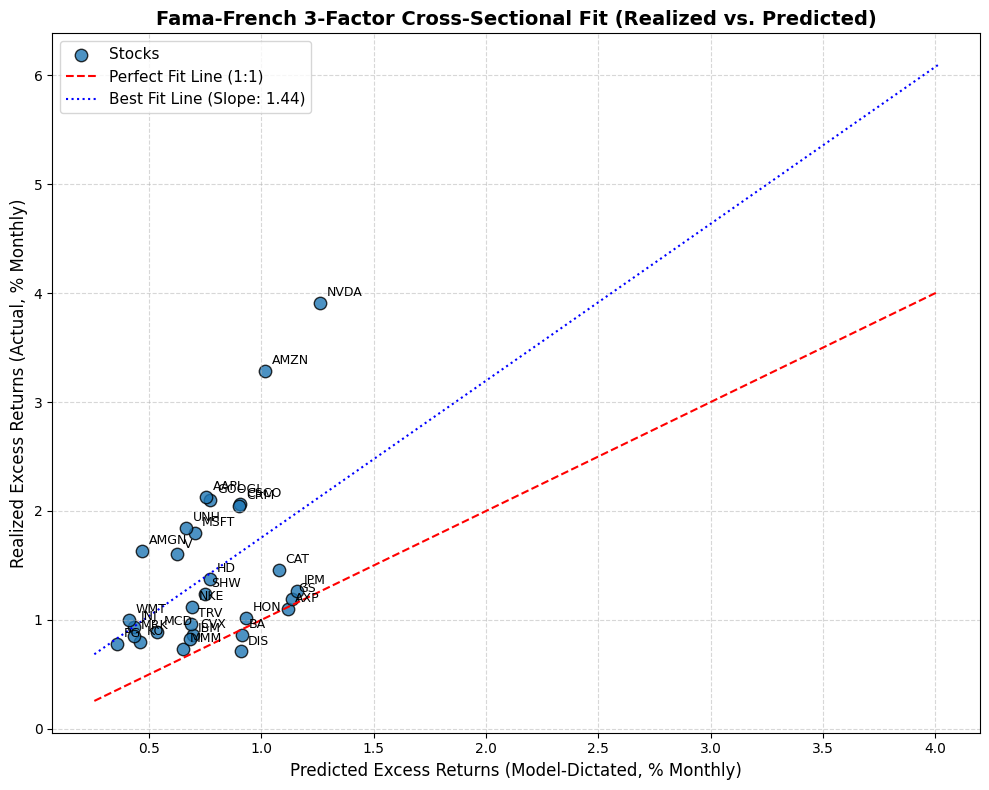

In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# --- 1. Compute empirical risk premia lambda (monthly average factor excess returns) ---
merged_factors = pd.concat([returns_m, ff3_m], axis=1, join='inner').dropna(subset=['Mkt-RF', 'SMB', 'HML', 'RF'])

lambda_mkt = merged_factors['Mkt-RF'].mean()
lambda_smb = merged_factors['SMB'].mean()
lambda_hml = merged_factors['HML'].mean()

print("=== Empirical Factor Risk Premia (Monthly Mean) ===")
print(f"lambda_Mkt-RF: {lambda_mkt:.6f} ({lambda_mkt*12*100:.2f}% annualized)")
print(f"lambda_SMB:    {lambda_smb:.6f} ({lambda_smb*12*100:.2f}% annualized)")
print(f"lambda_HML:    {lambda_hml:.6f} ({lambda_hml*12*100:.2f}% annualized)\n")

# --- 2. Estimate Beta Loadings (beta_i) and Realized Returns for each stock ---
portfolio_stats = []

for ticker in tickers:
    y_raw = returns_m[ticker].dropna()
    if y_raw.empty:
        continue

    stock_data = pd.concat([y_raw, ff3_m], axis=1, join='inner').dropna()
    if stock_data.empty:
        continue

    y_excess = stock_data[ticker] - stock_data['RF']

    X_ff3 = sm.add_constant(stock_data[['Mkt-RF', 'SMB', 'HML']])
    model_ff3 = sm.OLS(y_excess, X_ff3).fit()

    beta_mkt = model_ff3.params['Mkt-RF']
    beta_smb = model_ff3.params['SMB']
    beta_hml = model_ff3.params['HML']

    # Model-dictated expected excess return (lambda' * beta)
    predicted_excess = (beta_mkt * lambda_mkt) + (beta_smb * lambda_smb) + (beta_hml * lambda_hml)
    realized_excess = y_excess.mean()

    portfolio_stats.append({
        'Ticker': ticker,
        'Beta_Mkt': beta_mkt,
        'Beta_SMB': beta_smb,
        'Beta_HML': beta_hml,
        'Predicted_Excess': predicted_excess,
        'Realized_Excess': realized_excess
    })

df_cross_section = pd.DataFrame(portfolio_stats).set_index('Ticker')

# --- 3. Cross-sectional regression of Realized on Predicted ---
X_cs = sm.add_constant(df_cross_section['Predicted_Excess'])
y_cs = df_cross_section['Realized_Excess']
model_cs = sm.OLS(y_cs, X_cs).fit()

intercept_cs = model_cs.params['const']
slope_cs = model_cs.params['Predicted_Excess']
r2_cs = model_cs.rsquared

print("=== Cross-Sectional Regression Summary ===")
print(f"Intercept (gamma_0): {intercept_cs:.6f} (Expected: 0.000000)")
print(f"Slope (gamma_1):     {slope_cs:.6f} (Expected: 1.000000)")
print(f"Cross-sectional R2:  {r2_cs:.4f}\n")

# --- 4. Plot Realized vs. Predicted Excess Returns ---
plt.figure(figsize=(10, 8))
plt.scatter(df_cross_section['Predicted_Excess'] * 100, df_cross_section['Realized_Excess'] * 100,
            color='#1f77b4', s=80, alpha=0.8, edgecolor='k', label='Stocks')

for ticker, row in df_cross_section.iterrows():
    plt.annotate(ticker, (row['Predicted_Excess']*100, row['Realized_Excess']*100),
                 textcoords="offset points", xytext=(5,5), ha='left', fontsize=9)

# Perfect fit line (1:1 line)
min_val = min(df_cross_section['Predicted_Excess'].min(), df_cross_section['Realized_Excess'].min()) * 100 - 0.1
max_val = max(df_cross_section['Predicted_Excess'].max(), df_cross_section['Realized_Excess'].max()) * 100 + 0.1
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Fit Line (1:1)')

# Regression line
fit_line_x = np.linspace(min_val/100, max_val/100, 100)
fit_line_y = intercept_cs + slope_cs * fit_line_x
plt.plot(fit_line_x*100, fit_line_y*100, color='blue', linestyle=':', label=f'Best Fit Line (Slope: {slope_cs:.2f})')

plt.xlabel('Predicted Excess Returns (Model-Dictated, % Monthly)', fontsize=12)
plt.ylabel('Realized Excess Returns (Actual, % Monthly)', fontsize=12)
plt.title('Fama-French 3-Factor Cross-Sectional Fit (Realized vs. Predicted)', fontsize=14, fontweight='bold')
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()